# Análisis de clasificaciones incorrectas — Firewatch

Este notebook examina **únicamente las predicciones finales del mejor modelo**, elegido previamente mediante validación cruzada. No entrena modelos ni ajusta hiperparámetros. Las hipótesis sobre causas de errores son interpretaciones, no explicaciones causales demostradas.

## 1. Cargar las predicciones del test
**Antes de empezar:** ejecutar `entrenamiento.ipynb` hasta la sección **Exportar resultados**. Este archivo genera `resultados/predicciones_test.csv`.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

candidates = [Path('../resultados/predicciones_test.csv'), Path('resultados/predicciones_test.csv')]
archivo = next((p for p in candidates if p.is_file()), None)
if archivo is None:
    raise FileNotFoundError('Falta resultados/predicciones_test.csv. Ejecuta primero la sección de exportación del notebook de entrenamiento.')
pred = pd.read_csv(archivo)
required = {'review', 'y_real', 'y_pred', 'modelo'}
assert required.issubset(pred.columns), f'Faltan columnas: {required - set(pred.columns)}'
assert pred[['y_real', 'y_pred']].notna().all().all(), 'Hay etiquetas o predicciones vacías.'
assert pred['y_real'].isin([0,1]).all() and pred['y_pred'].isin([0,1]).all(), 'Las etiquetas deben ser 0/1.'
assert pred['modelo'].nunique() == 1, 'Se esperaba un único modelo seleccionado.'
pred['review'] = pred['review'].fillna('').astype(str)
pred['y_real'] = pred['y_real'].astype(int)
pred['y_pred'] = pred['y_pred'].astype(int)
print('Modelo:', pred['modelo'].iloc[0], '| Reseñas test:', len(pred))
display(pred.head(3))

Modelo: SVM lineal | Reseñas test: 10575


,indice_original,review,y_real,y_pred,modelo
0,16688,This is a slow paced story told through the ra...,1,1,SVM lineal
1,23862,Its not a game. There is a story and you are a...,0,0,SVM lineal
2,45265,"This game was not long, only about 4-5 hour. I...",1,1,SVM lineal


## 2. Resumen de aciertos y errores
Los resultados se interpretan como **0 = negativa** y **1 = positiva**. Definimos:
- **Falso positivo (FP):** reseña negativa predicha como positiva.
- **Falso negativo (FN):** reseña positiva predicha como negativa.

,Tipo,Cantidad
0,Correcta,9891
1,Falso negativo (positiva → negativa),460
2,Falso positivo (negativa → positiva),224


Errores: 684 de 10575
              precision    recall  f1-score   support

    Negativa       0.68      0.81      0.74      1210
    Positiva       0.98      0.95      0.96      9365

    accuracy                           0.94     10575
   macro avg       0.83      0.88      0.85     10575
weighted avg       0.94      0.94      0.94     10575



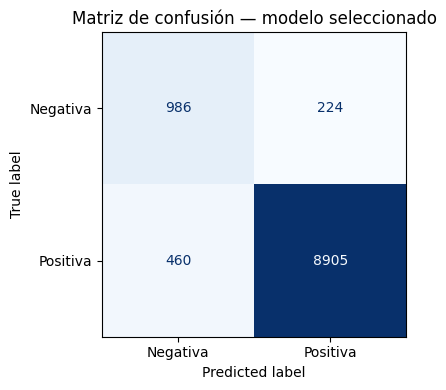

In [3]:
pred['acierto'] = pred['y_real'].eq(pred['y_pred'])
pred['tipo_resultado'] = np.select(
    [pred['y_real'].eq(0) & pred['y_pred'].eq(1),
     pred['y_real'].eq(1) & pred['y_pred'].eq(0)],
    ['Falso positivo (negativa → positiva)', 'Falso negativo (positiva → negativa)'],
    default='Correcta'
)
display(pred['tipo_resultado'].value_counts().rename_axis('Tipo').reset_index(name='Cantidad'))
print('Errores:', (~pred['acierto']).sum(), 'de', len(pred))
print(classification_report(pred['y_real'], pred['y_pred'], labels=[0,1],
                            target_names=['Negativa','Positiva'], zero_division=0))
fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(pred['y_real'], pred['y_pred'], labels=[0,1],
                                        display_labels=['Negativa','Positiva'],
                                        ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Matriz de confusión — modelo seleccionado')
plt.tight_layout(); plt.show()

## 3. Ejemplos concretos de errores
Se muestran hasta **5 falsos positivos y 5 falsos negativos**. Se usa muestreo reproducible para no escoger solamente ejemplos llamativos. Si hay menos de 5, se muestran los disponibles.

In [4]:
errores = pred.loc[~pred['acierto']].copy()
if errores.empty:
    print('No se detectaron errores en este conjunto de prueba.')
else:
    muestras = []
    for etiqueta in ['Falso positivo (negativa → positiva)', 'Falso negativo (positiva → negativa)']:
        subset = errores.loc[errores['tipo_resultado'].eq(etiqueta)]
        if not subset.empty:
            muestras.append(subset.sample(n=min(5, len(subset)), random_state=42))
    ejemplos = pd.concat(muestras, ignore_index=True) if muestras else errores.head(0)
    ejemplos['etiqueta_real'] = ejemplos['y_real'].map({0:'Negativa', 1:'Positiva'})
    ejemplos['prediccion'] = ejemplos['y_pred'].map({0:'Negativa', 1:'Positiva'})
    pd.set_option('display.max_colwidth', 220)
    display(ejemplos[['review','etiqueta_real','prediccion','tipo_resultado']])

,review,etiqueta_real,prediccion,tipo_resultado
0,"So, I feel this game have too much hype. I sat through the entire session expecting it to get better but it turns out that there is no moment of glory nor any engaging story. :(",Negativa,Positiva,Falso positivo (negativa → positiva)
1,I mean...the ending? So much good work undone.,Negativa,Positiva,Falso positivo (negativa → positiva)
2,Forced myself to finish this with one playthrough 5 hours uninstall.,Negativa,Positiva,Falso positivo (negativa → positiva)
3,great great characters but the story so underwhelming and game is so clunky at times,Negativa,Positiva,Falso positivo (negativa → positiva)
4,Ending doesn't hit the same when you play the game like a schizoid (or if you are one like me)[spoiler]and are able to see her trying to manipulate you from the beginning.[/spoiler],Negativa,Positiva,Falso positivo (negativa → positiva)
5,Beautiful but the ending left me feeling unfulfilled and confused,Positiva,Negativa,Falso negativo (positiva → negativa)
6,Buggy physics ruined the moment a couple times but otherwise great game,Positiva,Negativa,Falso negativo (positiva → negativa)
7,"Not my usual kind of game but for £4 on sale I was very satisfied with this purchase. The art style was gorgeous and although a short game, the relationship built up between the protagonist and deuteragonist definit...",Positiva,Negativa,Falso negativo (positiva → negativa)
8,"Beutiful game, sadly too short.\r\n\r\n+ Graphics\r\n+ Map\r\n+ Story\r\n- Too short :C\r\n\r\n9/10",Positiva,Negativa,Falso negativo (positiva → negativa)
9,"for the first game, D is stand for Delilah. but at the end of the game, D is stand for Disappointment.",Positiva,Negativa,Falso negativo (positiva → negativa)


## 4. Explorar posibles patrones asociados a errores
La longitud del texto puede ser una pista descriptiva. **No prueba** por qué el modelo falló. Los casos deben leerse manualmente para evaluar sarcasmo, negaciones, sentimientos mixtos, jerga o falta de contexto.

,count,median,mean
acierto,,,
Incorrecta,684,34.0,73.00
Correcta,9891,24.0,54.61


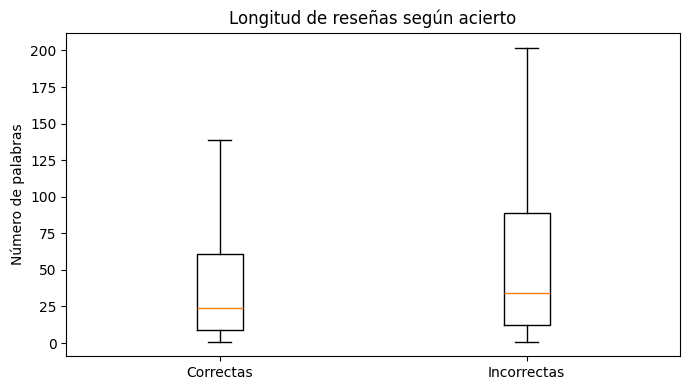

In [5]:
pred['n_palabras'] = pred['review'].str.split().str.len()
display(pred.groupby('acierto')['n_palabras'].agg(['count','median','mean']).rename(index={True:'Correcta',False:'Incorrecta'}).round(2))
fig, ax = plt.subplots(figsize=(7,4))
series = [pred.loc[pred['acierto'], 'n_palabras'], pred.loc[~pred['acierto'], 'n_palabras']]
ax.boxplot(series, tick_labels=['Correctas','Incorrectas'], showfliers=False)
ax.set(ylabel='Número de palabras', title='Longitud de reseñas según acierto')
plt.tight_layout(); plt.show()

## Análisis cualitativo de errores de clasificación

Con el objetivo de comprender las limitaciones del mejor modelo de clasificación, se seleccionaron tres reseñas del conjunto de prueba que fueron clasificadas incorrectamente. Se analizaron sus etiquetas reales, las predicciones realizadas y las posibles características lingüísticas que pudieron provocar los errores.

### Ejemplo 1: Crítica negativa expresada de manera indirecta

**Reseña original:**
"I mean...the ending? So much good work undone."

- **Etiqueta real:** Negativa.
- **Predicción del modelo:** Positiva.
- **Tipo de error:** Falso positivo.

**Interpretación cualitativa:**

La reseña expresa una opinión negativa sobre el desenlace del videojuego, indicando que el trabajo realizado anteriormente se vio perjudicado por el final. Sin embargo, utiliza la expresión "good work", que contiene palabras asociadas normalmente con valoraciones positivas.

Una posible explicación del error es que el modelo haya otorgado mayor importancia a estas palabras positivas sin interpretar adecuadamente el sentido completo de la oración. La crítica depende del contexto y de comprender que la expresión "undone" modifica negativamente la valoración anterior.

Este caso evidencia una posible limitación del modelo para identificar críticas indirectas y comprender relaciones complejas entre palabras.

### Ejemplo 4: Crítica contextual al desenlace del videojuego

**Reseña original:**
"Ending doesn't hit the same when you play the game like a schizoid (or if you are one like me) [spoiler]and are able to see her trying to manipulate you from the beginning.[/spoiler]"

- **Etiqueta real:** Negativa.
- **Predicción del modelo:** Positiva.
- **Tipo de error:** Falso positivo.

**Interpretación cualitativa:**

La reseña presenta una crítica al desenlace del videojuego, señalando que su impacto emocional disminuye cuando el jugador identifica anticipadamente las intenciones de un personaje.

Una posible causa de la clasificación incorrecta es que la opinión negativa no se expresa mediante palabras claramente negativas, sino a través de una explicación contextual relacionada con la narrativa del juego.

Además, la presencia de etiquetas como `[spoiler]` y referencias específicas a los personajes podría dificultar la identificación del sentimiento si el modelo no cuenta con suficiente información contextual.

Este ejemplo muestra una posible dificultad para reconocer valoraciones negativas que dependen de la interpretación de acontecimientos narrativos.

### Ejemplo 7: Sentimientos mixtos con valoración final positiva

**Reseña original (fragmento visible):**
"Not my usual kind of game but for £4 on sale I was very satisfied with this purchase. The art style was gorgeous and although a short game, the relationship built up between the protagonist and deuteragonist definit..."

- **Etiqueta real:** Positiva.
- **Predicción del modelo:** Negativa.
- **Tipo de error:** Falso negativo.

**Interpretación cualitativa:**

En el fragmento disponible, el usuario expresa una valoración general positiva del videojuego, destacando su satisfacción con la compra, el estilo artístico y la relación entre los personajes.

Sin embargo, también incluye expresiones que podrían interpretarse como negativas, como "Not my usual kind of game" y "short game".

Una posible explicación es que el modelo haya otorgado demasiado peso a estas expresiones, sin considerar suficientemente las valoraciones positivas presentes en el texto, como "very satisfied" y "gorgeous".

Este caso sugiere una posible dificultad para identificar el sentimiento predominante cuando una reseña combina observaciones negativas con una recomendación positiva.

### Conclusión del análisis cualitativo

Los tres ejemplos permiten identificar posibles dificultades del modelo para interpretar correctamente el sentimiento de reseñas que contienen críticas indirectas, referencias narrativas específicas o valoraciones mixtas.

En los primeros dos ejemplos el modelo clasificó reseñas negativas como positivas, mientras que en el tercer ejemplo ocurrió lo contrario.

Estos resultados sugieren que el modelo podría depender de patrones léxicos que no siempre representan adecuadamente el significado global de una reseña. Sin embargo, las causas propuestas son hipótesis interpretativas y no explicaciones verificadas del comportamiento interno del modelo.

Por tanto, el análisis evidencia la importancia de complementar las métricas cuantitativas con una revisión cualitativa de las predicciones incorrectas.

## 6. Exportación de datos
No se reentrena ni se modifica el modelo. El test se utiliza únicamente para **describir** el desempeño final.

In [6]:
if not errores.empty:
    destino = archivo.parent / 'ejemplos_errores_test.csv'
    ejemplos.to_csv(destino, index=False, encoding='utf-8-sig')
    print('Ejemplos exportados:', destino.resolve())
else:
    print('No hay errores que exportar.')

Ejemplos exportados: C:\Users\javie\Desktop\Tareas\S8\IA\proyecto2_IA\resultados\ejemplos_errores_test.csv
